# Task 10: Correlation Analysis

**Objective:** Explore potential correlations between factors.

**Steps:**
1. Select age, investment duration and expected return.
2. Use correlation coefficients and scatter plots to explore the relationships.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

df = pd.read_csv("../data/Data_set_2.csv")

In [2]:
duration_map = {"Less than 1 year": 0.5, "1-3 years": 2, "3-5 years": 4, "More than 5 years": 6}
expect_map = {"10%-20%": 15, "20%-30%": 25, "30%-40%": 35}

df["Duration_years"] = df["Duration"].map(duration_map)
df["Expected_return"] = df["Expect"].map(expect_map)

cols = ["age", "Duration_years", "Expected_return"]
df[cols].describe().round(2)

,age,Duration_years,Expected_return
count,40.00,40.00,40.0
mean,27.80,2.98,25.5
std,3.56,1.22,4.5
min,21.00,0.50,15.0
25%,25.75,2.00,25.0
50%,27.00,3.00,25.0
75%,30.00,4.00,25.0
max,35.00,6.00,35.0


In [3]:
corr = df[cols].corr(method="spearman").round(2)
corr

,age,Duration_years,Expected_return
age,1.00,0.04,-0.10
Duration_years,0.04,1.00,0.26
Expected_return,-0.10,0.26,1.00


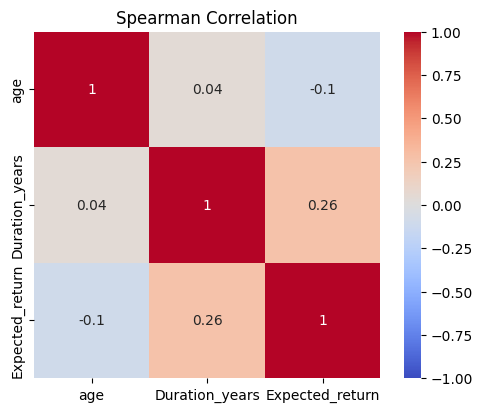

In [4]:
plt.figure(figsize=(6, 4.5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Spearman Correlation")
plt.savefig("../outputs/charts/task10_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
pairs = [("age", "Duration_years"), ("age", "Expected_return"), ("Duration_years", "Expected_return")]

rows = []
for a, b in pairs:
    rho, p = spearmanr(df[a], df[b])
    rows.append([a, b, round(rho, 3), round(p, 3)])

pd.DataFrame(rows, columns=["variable_1", "variable_2", "spearman_rho", "p_value"])

,variable_1,variable_2,spearman_rho,p_value
0,age,Duration_years,0.044,0.786
1,age,Expected_return,-0.103,0.525
2,Duration_years,Expected_return,0.259,0.107


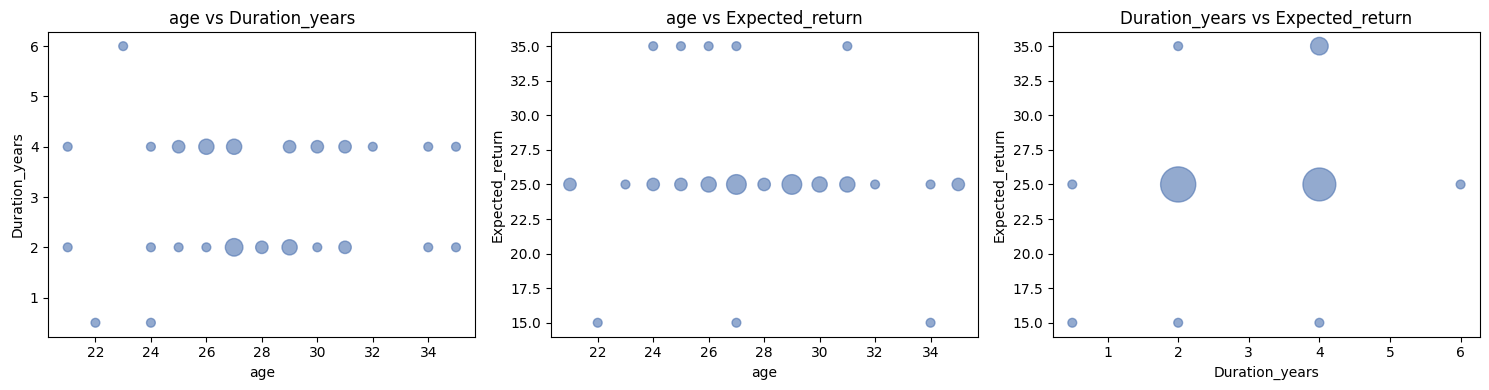

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (a, b) in zip(axes, pairs):
    size = df.groupby([a, b]).size().reset_index(name="n")
    ax.scatter(size[a], size[b], s=size["n"] * 40, alpha=0.6, color="#4C72B0")
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(a + " vs " + b)

plt.tight_layout()
plt.savefig("../outputs/charts/task10_scatter_plots.png", dpi=150, bbox_inches="tight")
plt.show()

## Finding

I compared age, planned investment duration and expected return. Duration and expected return were given as ranges, so I converted them to midpoints (the same mapping as Task 8, and 15, 25 and 35 for the return ranges). Because these two variables are ordered categories and many answers are tied, I used Spearman correlation instead of Pearson.

- Age and duration: rho = 0.04 (p = 0.79)
- Age and expected return: rho = -0.10 (p = 0.53)
- Duration and expected return: rho = 0.26 (p = 0.11)

None of these is statistically significant at the 5% level. The only pattern worth noting is a weak positive link between duration and expected return (people planning longer holding periods expect somewhat higher returns), but with 40 respondents it cannot be confirmed. Correlation here also says nothing about cause.